# MOP 3231 · Task 3 — Midterm Project: Will the Client Subscribe? (Bank Marketing)

**Student:** Imamsidikov · **Data:** `data/train.csv` (32,940 labelled calls) and `data/test.csv` (8,236 calls to score),
derived from UCI Bank Marketing (`bank-additional-full.csv`, CC BY 4.0)

| Part | Topic |
|---|---|
| 0 | Setup, versions, SEED |
| 1 | Loading and checking the data |
| 2 | EDA: the target and the numeric features |
| 3 | EDA: the categorical features, `unknown`, `pdays = 999` and `duration` |
| 4 | Validation split and the preprocessing pipeline |
| 5 | Baselines and stronger models |
| 6 | Cross-validation and tuning |
| 7 | Final evaluation and threshold |
| 8 | Refit, save, reload and score `test.csv` |

This is a teaching dataset, not evidence about real banks or clients.

## Part 0 · Setup

Virtual environment `.Imamsidikov_ML_task_3` (Python 3.12) with the pinned `requirements.txt`; Jupyter is only the tool
and stays out of it.

**SEED = 2954**: the last four digits of my student ID (S24072954). It seeds every split, fold and model.

In [1]:
import sys

import joblib
import matplotlib
import numpy
import pandas
import scipy
import sklearn

print(sys.version.split()[0], numpy.__version__, scipy.__version__, pandas.__version__,
      matplotlib.__version__, sklearn.__version__, joblib.__version__)

3.12.12 2.3.4 1.16.3 2.3.3 3.10.7 1.7.2 1.5.2


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 2954
TARGET = "y"

# Chart style: recessive grid and axes, one colour per class used the same way in every figure
NO, YES, NEUTRAL = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.titlesize": 11,
    "axes.grid": True,
    "grid.color": "#e7e6e1",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
})

## Part 1 · Loading and checking the data

In [3]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
print("train:", train.shape, "| test:", test.shape)
print("in train only:", sorted(set(train.columns) - set(test.columns)))
print("in test only: ", sorted(set(test.columns) - set(train.columns)))

train: (32940, 22) | test: (8236, 20)
in train only: ['duration', 'y']
in test only:  []


In [4]:
# Column types and the values seen in train
summary = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "n_unique": train.nunique(),
    "missing": train.isna().sum(),
    "example": train.iloc[0],
})
summary

,dtype,n_unique,missing,example
id,int64,32940,0,0
age,int64,76,0,39
job,object,12,0,management
marital,object,4,0,single
education,object,8,0,basic.9y
default,object,3,0,unknown
housing,object,3,0,yes
loan,object,3,0,no
contact,object,2,0,telephone
month,object,10,0,may


In [5]:
checks = {
    "missing cells in train": int(train.isna().sum().sum()),
    "missing cells in test": int(test.isna().sum().sum()),
    "train ids unique": train["id"].is_unique,
    "test ids unique": test["id"].is_unique,
    "train and test ids disjoint": set(train["id"]).isdisjoint(test["id"]),
    "duplicate rows in train (ignoring id)": int(train.drop(columns="id").duplicated().sum()),
    "target values": sorted(train[TARGET].unique()),
}
for name, value in checks.items():
    print(f"{name:40s} {value}")

missing cells in train                   0
missing cells in test                    0
train ids unique                         True
test ids unique                          True
train and test ids disjoint              True
duplicate rows in train (ignoring id)    0
target values                            ['no', 'yes']


In [6]:
# Same categories in train and test? A level seen only in test would need handle_unknown in the encoder.
categorical = [c for c in test.columns if test[c].dtype == object]
numeric = [c for c in test.columns if c not in categorical and c != "id"]
for c in categorical:
    only_test = set(test[c]) - set(train[c])
    if only_test:
        print(c, "levels only in test:", only_test)
print(len(categorical), "categorical:", categorical)
print(len(numeric), "numeric:", numeric)

10 categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
9 numeric: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


**What the checks say**

- No missing cells (`NaN`) in either file, unique and disjoint `id`s, no duplicate rows. Missing information is coded
  as values instead: the string `unknown` in six categorical columns and `pdays = 999` (Part 3).
- `train.csv` has two columns `test.csv` lacks: the target `y` and `duration`. A model can only use what `test.csv`
  has, so the feature set is the 19 columns of `test.csv` minus `id`: 10 categorical and 9 numeric.
- `id` is a shuffled row number added when the files were made. It carries no information and is not a feature.

## Part 2 · EDA: the target and the numeric features

### The target

In [7]:
y_counts = train[TARGET].value_counts()
yes_rate = (train[TARGET] == "yes").mean()
print(y_counts.to_string())
print(f"subscription rate: {yes_rate:.3f}  (about 1 in {1 / yes_rate:.0f} calls)")
print(f"accuracy of always answering 'no': {1 - yes_rate:.3f}")

y
no     29229
yes     3711
subscription rate: 0.113  (about 1 in 9 calls)
accuracy of always answering 'no': 0.887


About 11 % of calls end in a subscription. The classes are imbalanced, so **accuracy is a weak metric** here: the
useless model that always says "no" already scores about 0.89. Models will be compared on metrics that look at the
`yes` class (ROC AUC, average precision / PR AUC, precision and recall of `yes`), and every split and fold will be
**stratified** on `y` so each part keeps the 11 % rate.

### Numeric features

In [8]:
train[numeric].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,32940.0,40.04,10.43,17.00,32.00,38.00,47.00,98.00
campaign,32940.0,2.55,2.73,1.00,1.00,2.00,3.00,56.00
pdays,32940.0,961.44,189.46,0.00,999.00,999.00,999.00,999.00
previous,32940.0,0.17,0.50,0.00,0.00,0.00,0.00,7.00
emp.var.rate,32940.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,32940.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,32940.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,32940.0,3.62,1.74,0.63,1.34,4.86,4.96,5.04
nr.employed,32940.0,5167.03,72.39,4963.60,5099.10,5191.00,5228.10,5228.10


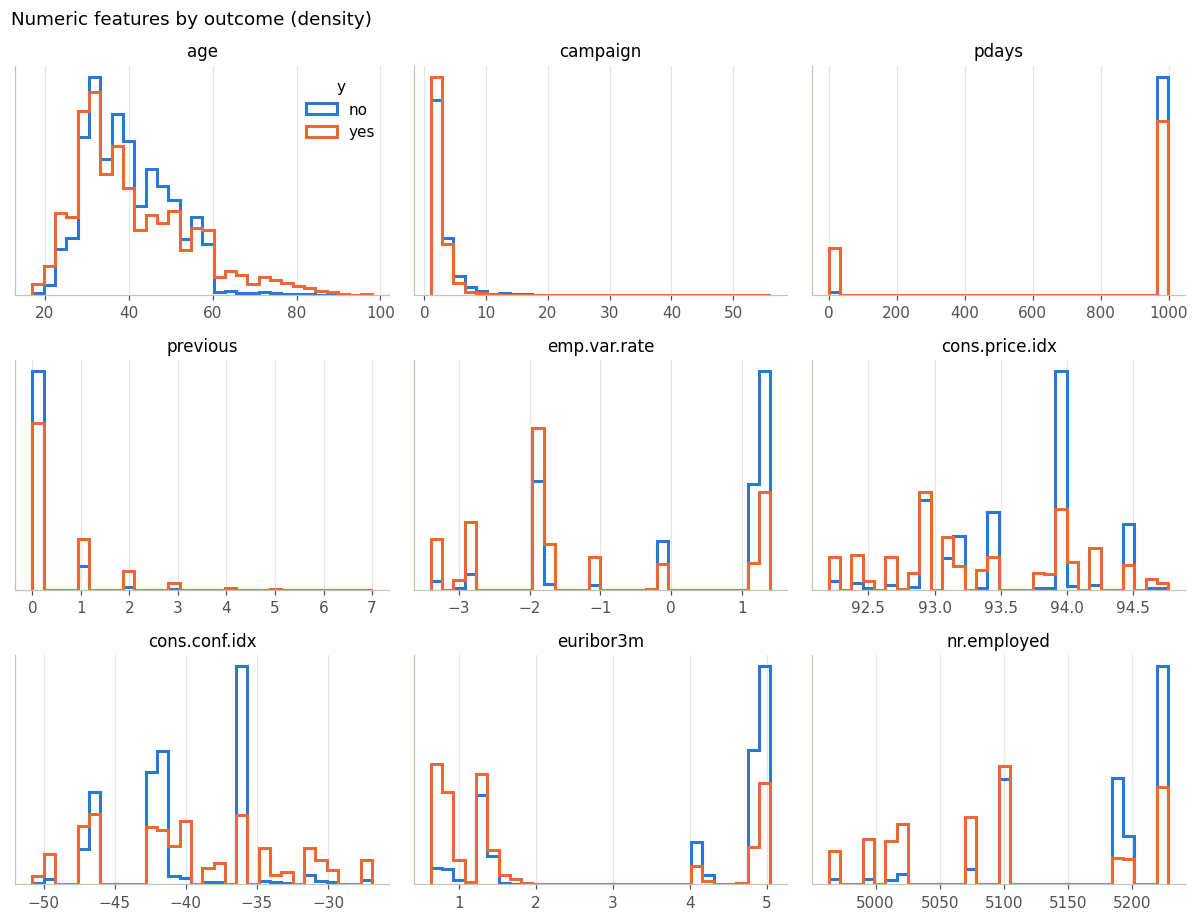

In [9]:
# Distribution of each numeric feature by class (densities, so the small 'yes' class is visible)
fig, axes = plt.subplots(3, 3, figsize=(11, 8.5))
for ax, col in zip(axes.flat, numeric):
    values = train[col]
    bins = np.histogram_bin_edges(values, bins=30)
    for label, color in (("no", NO), ("yes", YES)):
        ax.hist(values[train[TARGET] == label], bins=bins, density=True, histtype="step",
                linewidth=2, color=color, label=label)
    ax.set_title(col)
    ax.set_yticks([])
axes.flat[0].legend(title="y")
fig.suptitle("Numeric features by outcome (density)", x=0.01, ha="left")
fig.tight_layout()
plt.show()

In [10]:
# Medians by class, and how skewed / concentrated each column is
by_class = train.groupby(TARGET)[numeric].median().T
by_class["share of most common value"] = [train[c].value_counts(normalize=True).iloc[0] for c in numeric]
by_class["skew"] = train[numeric].skew()
by_class.round(3)

y,no,yes,share of most common value,skew
age,38.000,37.000,0.047,0.776
campaign,2.000,2.000,0.428,4.779
pdays,999.000,999.000,0.962,-4.846
previous,0.000,0.000,0.864,3.850
emp.var.rate,1.100,-1.800,0.396,-0.726
cons.price.idx,93.918,93.200,0.187,-0.235
cons.conf.idx,-41.800,-40.300,0.187,0.303
euribor3m,4.857,1.266,0.069,-0.710
nr.employed,5195.800,5099.100,0.396,-1.044


In [11]:
# The five economic indicators are monthly/quarterly series, so they move together
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
print("distinct values:", train[macro].nunique().to_dict())
train[macro].corr().round(2)

distinct values: {'emp.var.rate': 10, 'cons.price.idx': 26, 'cons.conf.idx': 26, 'euribor3m': 316, 'nr.employed': 11}


,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
emp.var.rate,1.00,0.78,0.19,0.97,0.91
cons.price.idx,0.78,1.00,0.05,0.69,0.52
cons.conf.idx,0.19,0.05,1.00,0.27,0.10
euribor3m,0.97,0.69,0.27,1.00,0.95
nr.employed,0.91,0.52,0.10,0.95,1.00


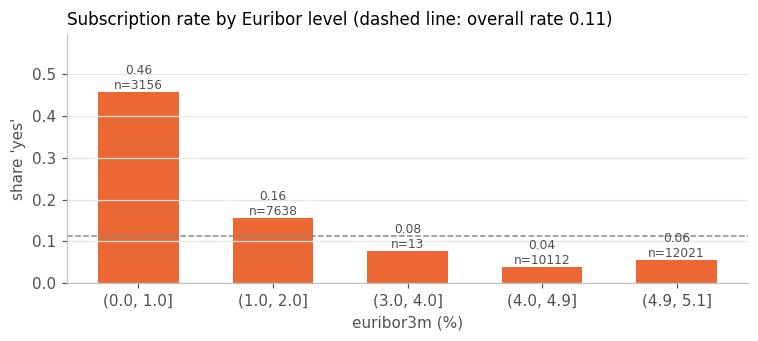

In [12]:
# Subscription rate across the range of the 3-month Euribor rate
bins = pd.cut(train["euribor3m"], bins=[0, 1, 2, 3, 4, 4.9, 5.1])
rate = train.groupby(bins, observed=True)[TARGET].apply(lambda s: (s == "yes").mean())
count = bins.value_counts().reindex(rate.index)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(rate.index.astype(str), rate.values, width=0.6, color=YES)
ax.axhline(yes_rate, color=NEUTRAL, linewidth=1, linestyle="--")
for i, (r, n) in enumerate(zip(rate.values, count.values)):
    ax.text(i, r, f"{r:.2f}\nn={n}", ha="center", va="bottom", fontsize=8, color="#52514e")
ax.set_xlabel("euribor3m (%)")
ax.set_ylabel("share 'yes'")
ax.set_ylim(0, rate.max() * 1.3)
ax.grid(axis="x", visible=False)
ax.set_title(f"Subscription rate by Euribor level (dashed line: overall rate {yes_rate:.2f})", loc="left")
fig.tight_layout()
plt.show()

**What the numeric features say**

- **The economic indicators carry the strongest numeric signal.** Median `euribor3m` is 4.86 for `no` and 1.27 for
  `yes`; below 1 % the subscription rate is 0.46, above 4 % it is 0.04–0.06. `emp.var.rate` and `nr.employed` show the
  same split. These columns have very few distinct values (10 for `emp.var.rate`, 11 for `nr.employed`) because they
  are monthly or quarterly figures: they record *when* the call was made, so they act as a marker of the campaign
  period as much as of the economy.
- `emp.var.rate`, `euribor3m` and `nr.employed` are almost the same variable (correlations 0.91–0.97). That does not
  hurt prediction, but it makes the individual coefficients of a linear model unstable, so I will not read meaning
  into them one by one. Regularisation (the default in `LogisticRegression`) keeps them in check.
- `age`: `yes` is more common at both ends: 0.24 for clients up to 24 and 0.46 over 60, against 0.08–0.11 between 30
  and 60. The relation is not monotonic, which a tree can pick up but a linear model only partly can.
- `campaign` (calls in this campaign) is very right-skewed (skew 4.8, maximum 56) and the rate falls as calls pile up:
  0.13 after one call, 0.06 after six or more.
- `previous` is 0 for 86 % of clients, but the rate climbs with it: 0.09 at 0, 0.21 at 1, 0.46 at 2.
- `pdays` is 999 in 96 % of rows; it is handled in Part 3.
- Scales differ by orders of magnitude (`nr.employed` ≈ 5,000, `cons.price.idx` ≈ 93, `euribor3m` ≈ 1–5), so
  scale-sensitive models (logistic regression, k-NN, SVM) need the numeric columns standardised. Trees do not.